# 4. Did any of it hold up?

Segments and product pairs are only useful if they say something about the future. So this notebook hides the last 90 days, builds everything from the earlier sales, and then looks at what those same customers and products did next.

The first version of this project stopped at describing the past.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from shoplens.clean import SHOPS, load, clean, open_shop
from shoplens.segmentation import GROUPS

plt.style.use("dark_background")
plt.rcParams.update({"figure.facecolor": "black", "axes.facecolor": "black", "axes.edgecolor": "#3a3b3e", "axes.grid": True,
                     "grid.color": "#1c1c1e", "figure.figsize": (11, 4.5), "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
WHITE, SILVER, GREY, JADE, RED = "#f2f2f0", "#d4d6da", "#8d8d90", "#5fd0a0", "#e0787a"
COLORS = dict(zip(GROUPS, [JADE, "#9fd9bd", WHITE, SILVER, "#c9a25a", GREY]))
money = lambda v, _=None: f"£{v:,.0f}"
UK, AMAZON, GROCERY = SHOPS

sales, removed = open_shop(UK)
from shoplens.forward import groups_next, pairs_next, split

before, after, cutoff = split(sales)
print(f"Built from sales up to {cutoff:%B %d, %Y}: {before.customer.nunique():,} customers")
print(f"Checked against the {after.when.dt.date.nunique()} trading days after it")

Built from sales up to September 10, 2011: 3,363 customers
Checked against the 78 trading days after it


## Did the customer segments predict who came back?

In [2]:
table = groups_next(sales)
table.style.format({"customers": "{:,.0f}", "came_back": "{:.0%}", "average_spend_after": "£{:,.0f}"})

,customers,came_back,average_spend_after
group,,,
Best customers,893,84%,"£1,979"
Regulars,676,64%,£520
New,237,45%,£259
Occasional,212,45%,£323
Going quiet,449,51%,£359
Lost,896,34%,£185
Everyone,"3,363",57%,£766


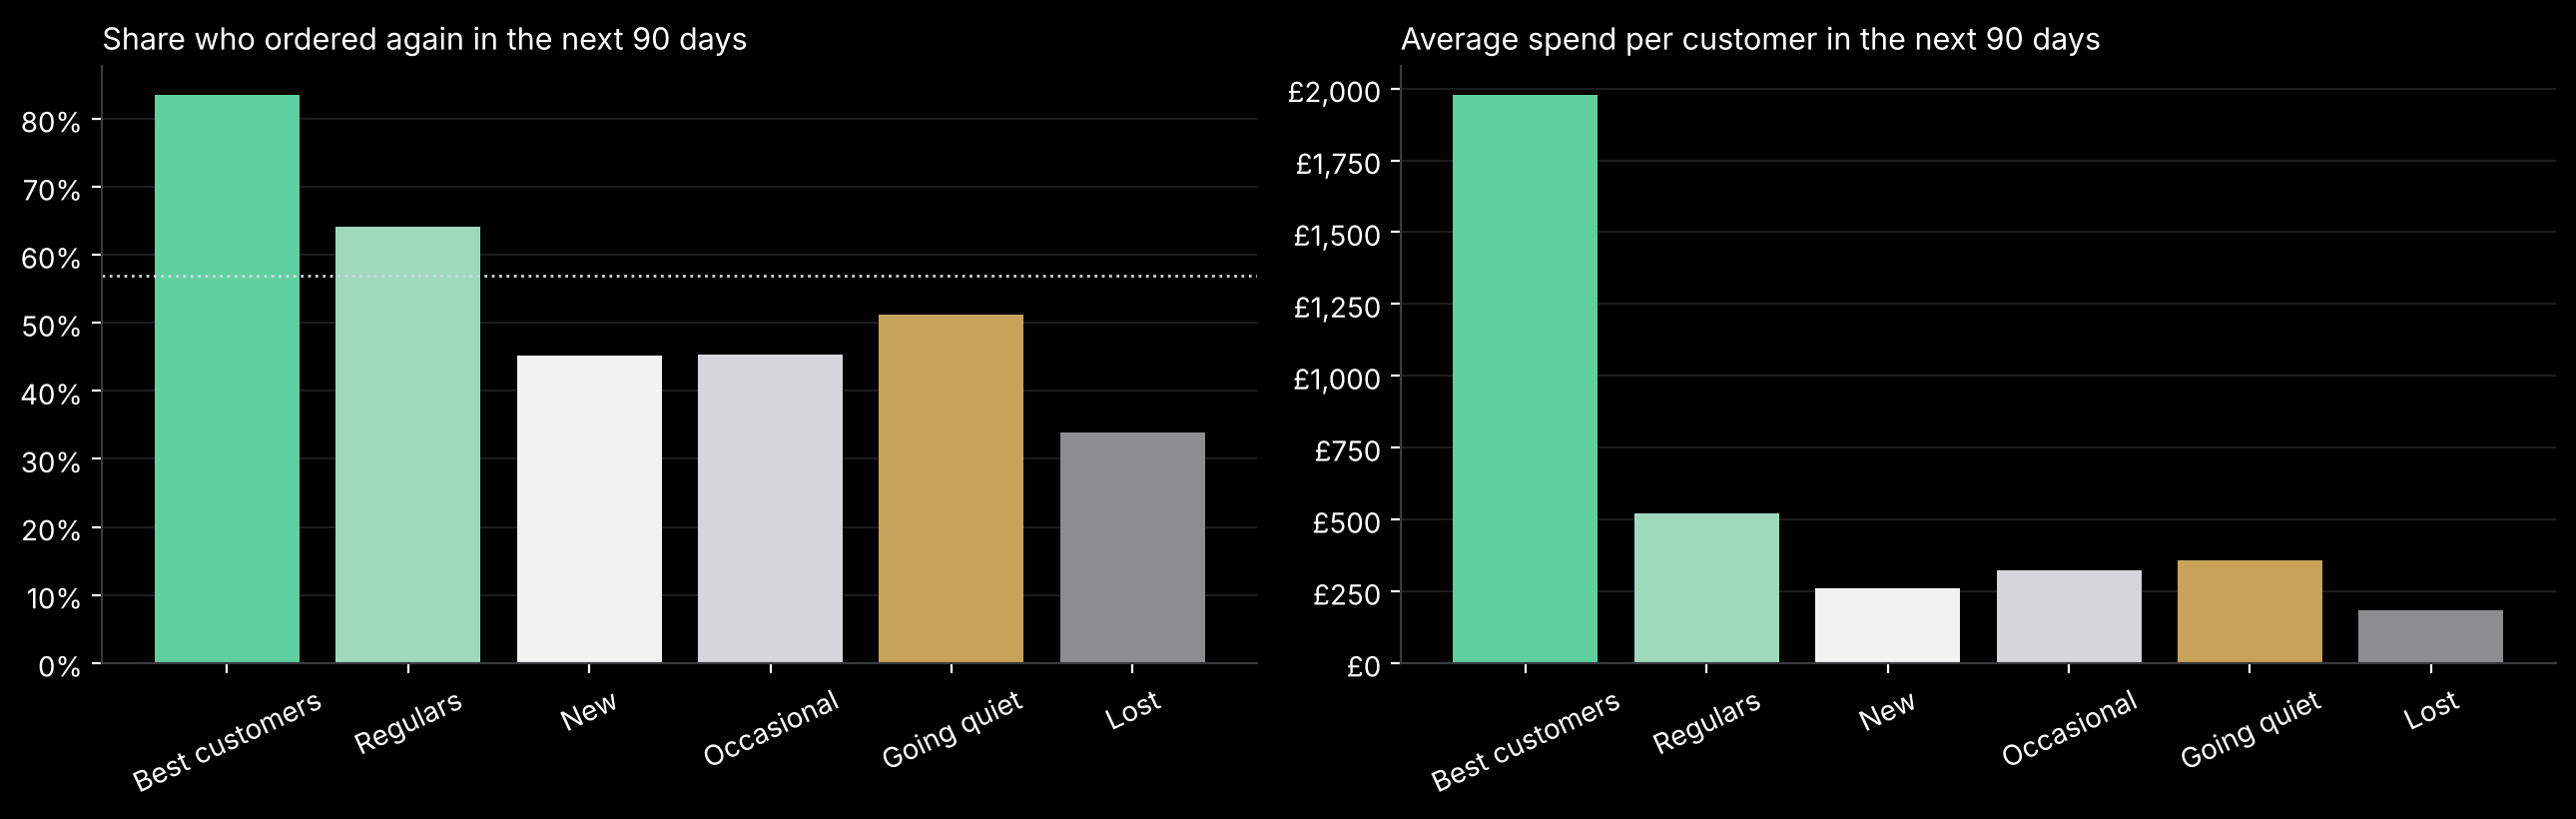

In [3]:
groups = table.drop("Everyone")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(groups.index, groups.came_back, color=[COLORS[g] for g in groups.index])
axes[0].axhline(table.loc["Everyone", "came_back"], color=SILVER, lw=1, ls=":"); axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[0].set_title("Share who ordered again in the next 90 days", loc="left", fontsize=11)
axes[1].bar(groups.index, groups.average_spend_after, color=[COLORS[g] for g in groups.index]); axes[1].yaxis.set_major_formatter(money)
axes[1].set_title("Average spend per customer in the next 90 days", loc="left", fontsize=11)
for ax in axes:
    ax.tick_params(axis="x", rotation=25); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

The dotted line is the rate for all customers. The order of the bars is the test: if the segments meant nothing, they would all sit near that line.

## Did the market basket pairs keep selling together?

The 50 strongest pairs from the earlier sales, measured again on the later ones.

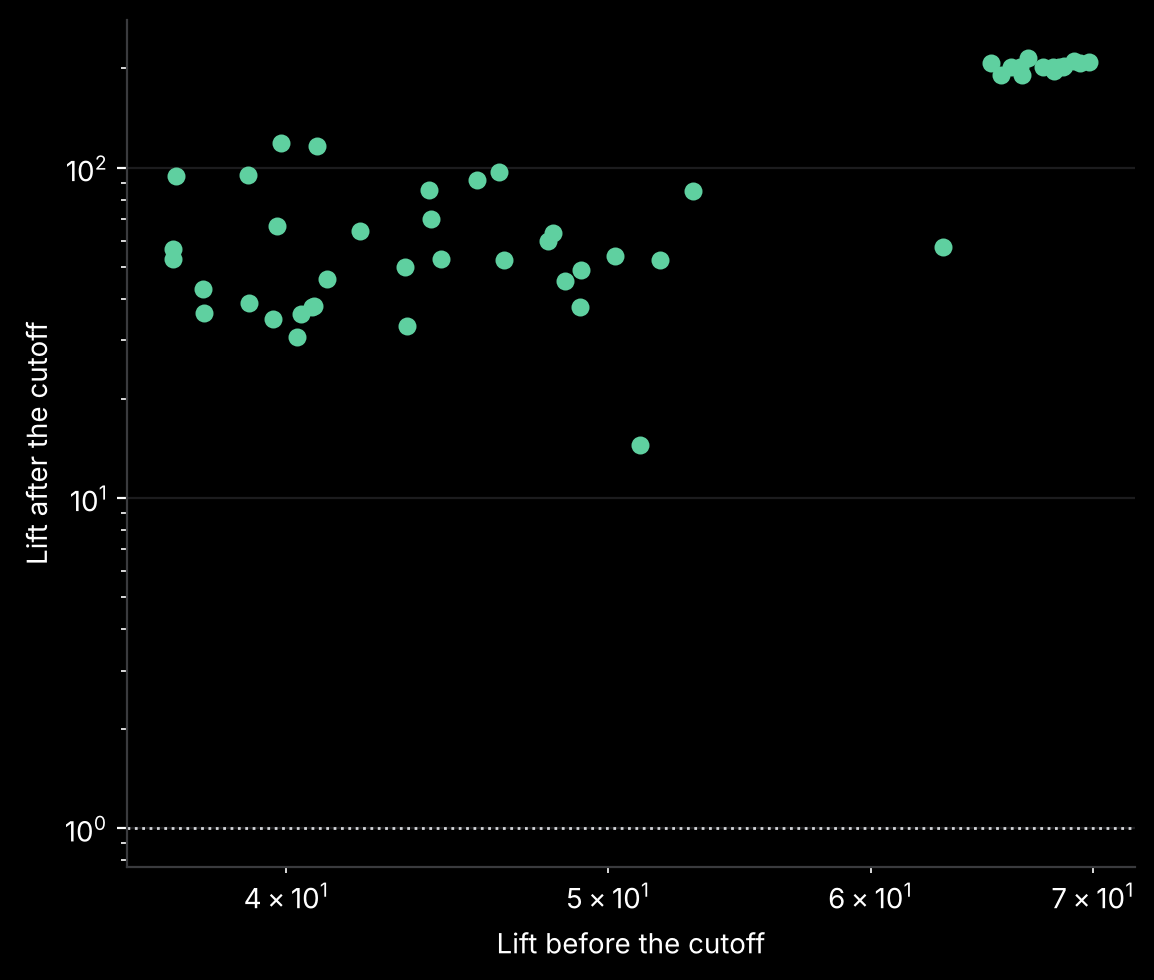

Pairs still bought together more than chance afterward: 50 of 50


In [4]:
checked = pairs_next(sales)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(checked.lift, checked.lift_after.clip(lower=0.5), color=JADE, s=30)
ax.axhline(1, color=SILVER, lw=1, ls=":"); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Lift before the cutoff"); ax.set_ylabel("Lift after the cutoff")
plt.show()
print(f"Pairs still bought together more than chance afterward: {(checked.lift_after > 1).sum()} of {len(checked)}")

## What this says

* **The segments predicted behavior.** Best customers came back at 84 percent and spent about ten times what Lost customers did. Regulars came next, then Going quiet, with Lost at the bottom.
* **Going quiet is a real warning, and not a lost cause.** Half of them still came back, against 64 percent of Regulars. They are worth contacting.
* **New customers are a coin flip.** Under half ordered again. The second order is where a shop wins or loses them.
* **Every one of the 50 strongest pairs kept selling together.** These are stable links, safe to build bundles and suggestions on.

One caution: the 90 days held back run from September into December, the busiest part of this shop's year. Return rates in a quiet season would be lower across the board, though the order of the segments should hold.